<a href="https://colab.research.google.com/github/ahmede9ka/CodeAlpha_Age_calulator/blob/main/closing_the_gap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Closing the gap: does a one-line task description change what a VLM sees?
**Runtime > Change runtime type > T4 GPU** before running.

In [ ]:
!pip install -q -U transformers accelerate bitsandbytes
import torch; print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [ ]:
# Upload 3-10 images (jpg/png)
import os
from google.colab import files
os.makedirs('data', exist_ok=True)
up = files.upload()
for name, content in up.items():
    open(f'data/{name}', 'wb').write(content)

Saving images (2).jpg to images (2).jpg
Saving images (1).jpg to images (1).jpg
Saving images.jpg to images.jpg


In [ ]:
import torch
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

MODEL_ID = "llava-hf/llava-1.5-7b-hf"
processor = AutoProcessor.from_pretrained(MODEL_ID)
model = LlavaForConditionalGeneration.from_pretrained(
    MODEL_ID,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16),
    device_map="auto",
)

processor_config.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/701 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/674 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/505 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

...

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/141 [00:00<?, ?B/s]

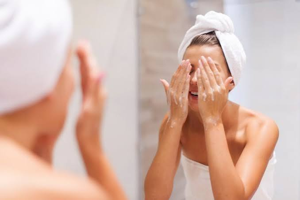

[no task]   The person in the image is currently washing their face with a towel wrapped around their head. They are likely to continue using the towel to dry their face after washing it. This suggests that they are taking care of their personal hygiene and grooming routine.
[with task] Based on the image, it is not possible to definitively determine if the person is married or not. However, the person is in the process of washing their face, which suggests that they are taking care of their personal hygiene. The next likely action for the person would be to rinse their face with water after applying the soap, and then proceed to dry their face using a towel.



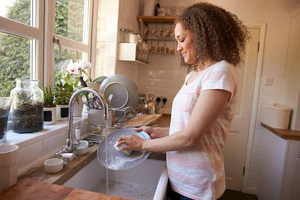

[no task]   The person is currently washing dishes in the kitchen sink. They are holding a dish and rinsing it under the faucet. After rinsing the dish, they will likely place it in the dishwasher or dry it off with a towel before putting it away.
[with task] Based on the image, it is not possible to definitively determine if the person is married. However, the woman is standing in a kitchen, washing dishes in a sink. It is likely that she will continue to wash the dishes and clean the kitchen after finishing the current task.



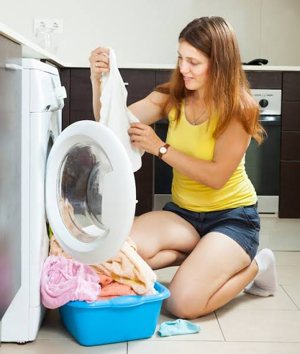

[no task]   The person is currently kneeling down next to a washing machine, holding a towel and possibly a cloth. They are likely in the process of washing clothes or other items. After they have finished handling the towel and cloth, they will probably start the washing machine to begin the washing process.
[with task] Based on the image, it is not possible to definitively determine if the person is married. However, the woman is seen kneeling down next to a washing machine, holding a towel, and possibly preparing to put clothes into the machine. This suggests that she is engaged in laundry tasks, which are typically associated with household chores. It is likely that she will continue to sort and load the clothes into the washing machine, and then proceed to operate the machine to wash the clothes.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json, pathlib
from PIL import Image

TASK = (
    "is this person married "

)

QUESTION = (
    "What is the person doing right now, and what will they probably do next?"
)

def ask(image, text):
    conv = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt = processor.apply_chat_template(conv, add_generation_prompt=True)
    inputs = processor(images=image, text=prompt, return_tensors="pt").to(model.device, torch.float16)
    ids = model.generate(**inputs, max_new_tokens=120, do_sample=False)
    return processor.decode(ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

results = []
for p in sorted(pathlib.Path("data").iterdir()):
    if p.suffix.lower() not in {".jpg", ".jpeg", ".png"}: continue
    img = Image.open(p).convert("RGB")
    a, b = ask(img, QUESTION), ask(img, f"{TASK} {QUESTION}")
    results.append({"image": p.name, "without_task": a, "with_task": b})
    display(img.resize((300, int(300*img.height/img.width))))
    print(f"[no task]   {a}\n[with task] {b}\n")

json.dump(results, open("results.json", "w"), indent=2)
from google.colab import files; files.download("results.json")